In [1]:
# ============================================================
# BRAIN TUMOR DETECTION USING DEEP LEARNING
# Optimized for: MacBook Air M5 (Apple Silicon), 24GB RAM
# Framework: TensorFlow-macos + TensorFlow-metal (GPU acceleration)
# Dataset: Kaggle "Brain Tumor MRI Dataset" (masoudnickparvar)
# ============================================================
# Copy each "# %%" block into its own Jupyter cell.
# ============================================================

# %% [1] ENVIRONMENT SETUP (run once in terminal, NOT in notebook)
# ------------------------------------------------------------
# Apple Silicon needs the macOS-specific TF build + Metal plugin.
# Run these in your terminal (ideally inside a fresh conda/venv env):
#
#   conda create -n braintumor python=3.10 -y
#   conda activate braintumor
#   pip install tensorflow-macos tensorflow-metal
#   pip install numpy pandas matplotlib seaborn scikit-learn opencv-python pillow groq requests kagglehub
#   pip install jupyter ipykernel
#   python -m ipykernel install --user --name braintumor
#
# For Offline AI Reports, also install Ollama (https://ollama.com)
# and run in your terminal: ollama run gemma4:12b

In [2]:
# %% [2] VERIFY GPU IS DETECTED
import tensorflow as tf
import numpy as np
import os
import time
import multiprocessing

print("TensorFlow version:", tf.__version__)
print("Physical devices:", tf.config.list_physical_devices())
print("GPU devices:", tf.config.list_physical_devices('GPU'))
print("CPU cores available:", multiprocessing.cpu_count())

TensorFlow version: 2.16.2
Physical devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
CPU cores available: 10


In [3]:
# %% [3] SET SEEDS FOR REPRODUCIBILITY
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [4]:
# %% [4] CONFIG — ALL TUNABLE PARAMETERS IN ONE PLACE
IMG_SIZE = (224, 224)      
IMG_SHAPE = (224, 224, 3)
BATCH_SIZE = 32             
EPOCHS_PHASE1 = 15          
EPOCHS_PHASE2 = 15          
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
NUM_CLASSES = len(CLASSES)
MODEL_SAVE_PATH = "brain_tumor_model.keras"

In [5]:
# %% [5] AUTOMATIC DATASET DOWNLOAD & PATH CONFIG
import kagglehub

print("[Status] Downloading dataset via kagglehub...")
# This automatically downloads, unzips, and caches the dataset on your Mac
download_path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Dataset downloaded to:", download_path)

# Dynamically route training and testing paths from the downloaded location
TRAIN_DIR = os.path.join(download_path, "Training")
TEST_DIR = os.path.join(download_path, "Testing")

def check_dataset():
    for split_dir in [TRAIN_DIR, TEST_DIR]:
        if not os.path.isdir(split_dir):
            print(f"WARNING: {split_dir} not found.")
            continue
        print(f"\n{split_dir}:")
        total = 0
        for cls in sorted(os.listdir(split_dir)):
            cls_path = os.path.join(split_dir, cls)
            if os.path.isdir(cls_path):
                count = len([f for f in os.listdir(cls_path)
                             if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
                print(f"  {cls}: {count} images")
                total += count
        print(f"  TOTAL: {total}")

check_dataset()

[Status] Downloading dataset via kagglehub...
Dataset downloaded to: /Users/krithvik/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2

/Users/krithvik/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Training:
  glioma: 1400 images
  meningioma: 1400 images
  notumor: 1400 images
  pituitary: 1400 images
  TOTAL: 5600

/Users/krithvik/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Testing:
  glioma: 400 images
  meningioma: 400 images
  notumor: 400 images
  pituitary: 400 images
  TOTAL: 1600


In [6]:
# %% [6] MODERN DATA PIPELINE & AUGMENTATION
# Note: Keep raw pixels in [0, 255] because EfficientNetB0 has its own internal Rescaling layer!
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.15,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    class_names=CLASSES
)

raw_val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    class_names=CLASSES
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    class_names=CLASSES,
    shuffle=False
)

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal", seed=SEED),
    tf.keras.layers.RandomRotation(0.05, seed=SEED),
    tf.keras.layers.RandomZoom(0.05, seed=SEED),
], name="mri_augmentation")

AUTOTUNE = tf.data.AUTOTUNE
train_gen = raw_train_ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_gen = raw_val_ds.prefetch(AUTOTUNE)


Found 4760 images belonging to 4 classes.
Found 840 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.
Class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Train samples: 4760
Val samples: 840
Test samples: 1600


In [7]:
# %% [7] HANDLE CLASS IMBALANCE
from sklearn.utils.class_weight import compute_class_weight

train_labels = train_gen.classes
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_labels),
    y=train_labels
)
class_weights = dict(enumerate(class_weights_array))
print("Class weights:", class_weights)

Class weights: {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0}


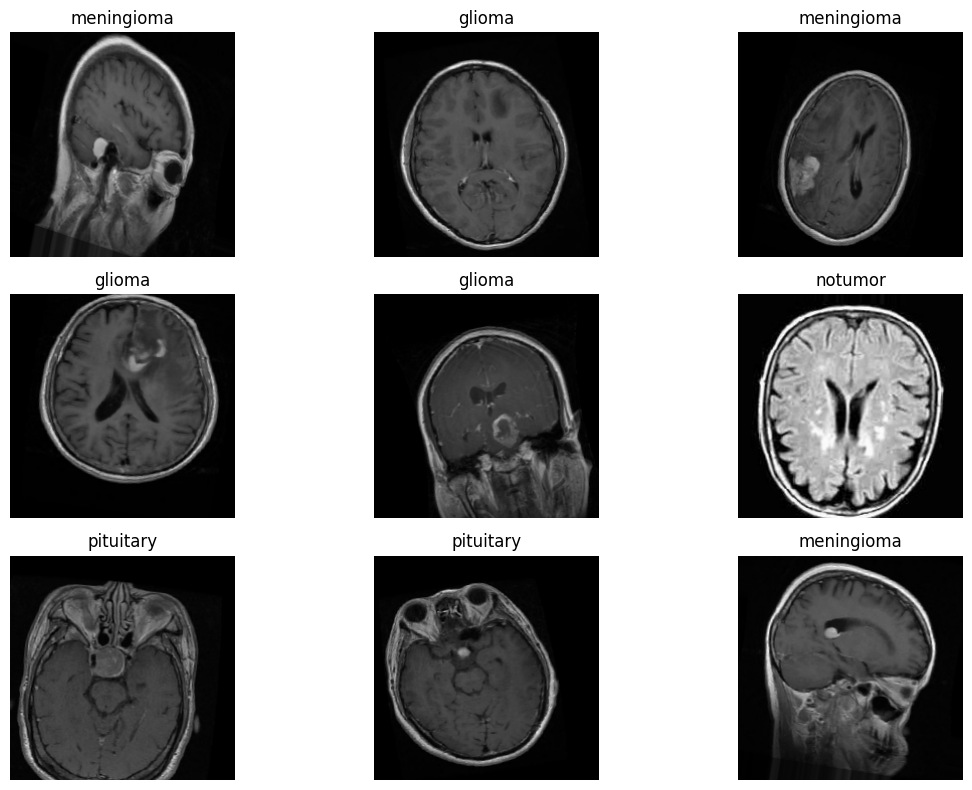

In [8]:
# %% [8] VISUALIZE A BATCH
import matplotlib.pyplot as plt

def show_sample_batch(generator):
    images, labels = next(generator)
    class_names = list(generator.class_indices.keys())
    plt.figure(figsize=(12, 8))
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])
        label_idx = np.argmax(labels[i])
        plt.title(class_names[label_idx])
        plt.axis("off")
    plt.tight_layout()
    plt.savefig("sample_batch.png")
    plt.show()

show_sample_batch(train_gen)

In [9]:
# %% [9] BUILD MODEL — TRANSFER LEARNING WITH EFFICIENTNETB0
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models

def build_model(input_shape=IMG_SHAPE, num_classes=NUM_CLASSES):
    base_model = EfficientNetB0(
        weights="imagenet",
        include_top=False,
        input_shape=input_shape
    )
    base_model.trainable = False  

    inputs = layers.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    return model, base_model

model, base_model = build_model()
model.summary()

2026-07-10 07:36:35.075970: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-07-10 07:36:35.076017: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-07-10 07:36:35.076023: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
2026-07-10 07:36:35.076048: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-07-10 07:36:35.076067: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,379,559 (16.71 MB)

 Trainable params: 329,476 (1.26 MB)

 Non-trainable params: 4,050,083 (15.45 MB)

In [10]:
# %% [10] COMPILE — PHASE 1 (frozen base)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

In [11]:
# %% [11] CALLBACKS
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks_phase1 = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1),
    ModelCheckpoint("best_model_phase1.keras", monitor="val_loss", save_best_only=True, verbose=1),
]

In [12]:
# %% [12] TRAIN — PHASE 1
start_time = time.time()

history1 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_PHASE1,
    class_weight=class_weights,
    callbacks=callbacks_phase1,
    verbose=1
)

print(f"Phase 1 training time: {(time.time() - start_time) / 60:.2f} minutes")

Epoch 1/15


2026-07-10 07:36:53.056837: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.2555 - auc: 0.5050 - loss: 1.8964
Epoch 1: val_loss improved from None to 1.39325, saving model to best_model_phase1.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 26s 155ms/step - accuracy: 0.2515 - auc: 0.5059 - loss: 1.8007 - val_accuracy: 0.2821 - val_auc: 0.5649 - val_loss: 1.3932 - learning_rate: 0.0010
Epoch 2/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.2386 - auc: 0.4947 - loss: 1.6619
Epoch 2: val_loss did not improve from 1.39325
149/149 ━━━━━━━━━━━━━━━━━━━━ 20s 131ms/step - accuracy: 0.2508 - auc: 0.5035 - loss: 1.6096 - val_accuracy: 0.2464 - val_auc: 0.5522 - val_loss: 1.4384 - learning_rate: 0.0010
Epoch 3/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.2612 - auc: 0.5112 - loss: 1.5283
Epoch 3: val_loss did not improve from 1.39325
149/149 ━━━━━━━━━━━━━━━━━━━━ 21s 137ms/step - accuracy: 0.2683 - auc: 0.5146 - loss: 1.5102 - val_accuracy: 0.2500 - val_auc: 0.5519 - val_loss: 1.4432 - learning_rate: 0

In [ ]:
# %% [13] FINE-TUNE — PHASE 2
base_model.trainable = True

# Freeze all but the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  
    loss="categorical_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

callbacks_phase2 = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-8, verbose=1),
    ModelCheckpoint("best_model_phase2.keras", monitor="val_loss", save_best_only=True, verbose=1),
]

start_time = time.time()

history2 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_PHASE2,
    class_weight=class_weights,
    callbacks=callbacks_phase2,
    verbose=1
)

print(f"Phase 2 fine-tuning time: {(time.time() - start_time) / 60:.2f} minutes")

Epoch 1/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - accuracy: 0.2504 - auc: 0.4971 - loss: 1.4438
Epoch 1: val_loss improved from None to 1.40429, saving model to best_model_phase2.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 34s 190ms/step - accuracy: 0.2592 - auc: 0.5139 - loss: 1.4202 - val_accuracy: 0.2500 - val_auc: 0.5465 - val_loss: 1.4043 - learning_rate: 1.0000e-05
Epoch 2/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.2929 - auc: 0.5528 - loss: 1.3814
Epoch 2: val_loss did not improve from 1.40429
149/149 ━━━━━━━━━━━━━━━━━━━━ 27s 178ms/step - accuracy: 0.3015 - auc: 0.5584 - loss: 1.3778 - val_accuracy: 0.2500 - val_auc: 0.5557 - val_loss: 1.4124 - learning_rate: 1.0000e-05
Epoch 3/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.3080 - auc: 0.5862 - loss: 1.3599
Epoch 3: val_loss improved from 1.40429 to 1.34405, saving model to best_model_phase2.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 31s 209ms/step - accuracy: 0.3105 - auc: 0.5815 - loss: 1.3617 - val_accuracy

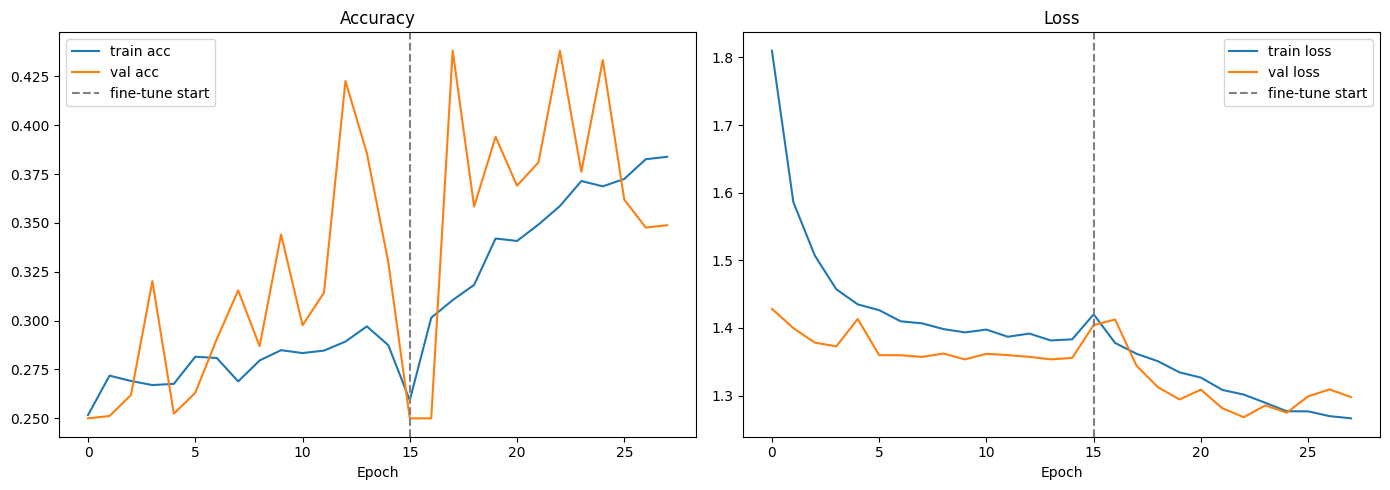

In [ ]:
# %% [14] PLOT TRAINING HISTORY
def plot_history(h1, h2):
    acc = h1.history['accuracy'] + h2.history['accuracy']
    val_acc = h1.history['val_accuracy'] + h2.history['val_accuracy']
    loss = h1.history['loss'] + h2.history['loss']
    val_loss = h1.history['val_loss'] + h2.history['val_loss']

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(acc, label="train acc")
    axes[0].plot(val_acc, label="val acc")
    axes[0].axvline(x=len(h1.history['accuracy']), color='gray', linestyle='--', label="fine-tune start")
    axes[0].set_title("Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(loss, label="train loss")
    axes[1].plot(val_loss, label="val loss")
    axes[1].axvline(x=len(h1.history['loss']), color='gray', linestyle='--', label="fine-tune start")
    axes[1].set_title("Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig("training_history.png")
    plt.show()

plot_history(history1, history2)

In [ ]:
# %% [15] EVALUATE ON TEST SET
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

test_loss, test_acc, test_auc = model.evaluate(test_gen, verbose=1)
print(f"\nTest Accuracy: {test_acc:.4f}")
print(f"Test AUC: {test_auc:.4f}")

y_true = test_gen.classes
y_pred_probs = model.predict(test_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASSES))

50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - accuracy: 0.4550 - auc: 0.7069 - loss: 1.2571

Test Accuracy: 0.4550
Test AUC: 0.7069
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 96ms/step

Classification Report:
              precision    recall  f1-score   support

      glioma       0.56      0.18      0.28       400
  meningioma       0.31      0.74      0.44       400
     notumor       0.70      0.58      0.63       400
   pituitary       0.66      0.31      0.42       400

    accuracy                           0.46      1600
   macro avg       0.56      0.46      0.44      1600
weighted avg       0.56      0.46      0.44      1600



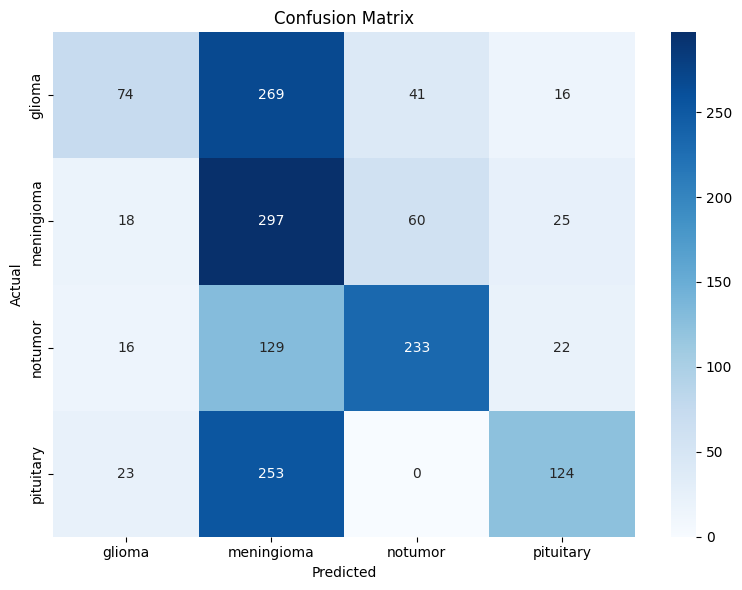

In [ ]:
# %% [16] CONFUSION MATRIX
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

In [ ]:
# %% [17] SAVE FINAL MODEL
model.save(MODEL_SAVE_PATH)
print(f"Model saved to {MODEL_SAVE_PATH}")

Model saved to brain_tumor_model.keras


In [ ]:
# %% [18] GRAD-CAM VISUALIZATION
import cv2

def get_last_conv_layer_name(model):
    for layer in reversed(model.layers[1].layers):
        if len(layer.output_shape) == 4:
            return layer.name
    raise ValueError("No conv layer found")

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    base = model.layers[1]  
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [base.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        class_idx = tf.argmax(predictions[0])
        loss = predictions[:, class_idx]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(class_idx.numpy())

def overlay_gradcam(img_path, model, last_conv_layer_name, alpha=0.4):
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=IMG_SIZE)
    img_array = tf.keras.preprocessing.image.img_to_array(img) / 255.0
    img_array_batch = np.expand_dims(img_array, axis=0)

    heatmap, class_idx = make_gradcam_heatmap(img_array_batch, model, last_conv_layer_name)

    heatmap_resized = cv2.resize(heatmap, IMG_SIZE)
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB) / 255.0

    superimposed = heatmap_color * alpha + img_array * (1 - alpha)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 3, 1)
    plt.imshow(img_array)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(superimposed)
    plt.title(f"Overlay — Predicted: {CLASSES[class_idx]}")
    plt.axis("off")

    plt.tight_layout()
    plt.savefig("gradcam_result.png")
    plt.show()

In [ ]:
# %% [19] SINGLE-IMAGE INFERENCE FUNCTION
def predict_single_image(img_path, model):
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=IMG_SIZE)
    # Feed raw pixel values in [0, 255] as expected by EfficientNetB0
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    preds = model.predict(img_array, verbose=0)[0]
    predicted_class = CLASSES[np.argmax(preds)]
    confidence = float(np.max(preds))

    print(f"Predicted: {predicted_class} ({confidence:.2%} confidence)")
    for cls, prob in zip(CLASSES, preds):
        print(f"  {cls}: {prob:.4f}")

    return predicted_class, confidence


In [ ]:
# %% [20] AI-GENERATED REPORT (Online via Groq OR Offline via Gemma 4 12B)
import requests
from groq import Groq

GROQ_API_KEY = "YOUR_GROQ_API_KEY_HERE"  # Change to your real key for online inference

def generate_report(predicted_class, confidence, use_offline=False):
    prompt = f"""A brain MRI classification model predicted class: {predicted_class} 
with confidence {confidence:.2%}. Write a short, plain-language technical note 
summarizing this result for a student project README. Do not give medical advice 
or imply this is a diagnostic tool — frame it strictly as a model output summary."""

    # --- OFFLINE EXECUTION (Gemma 4 12B via Local Ollama) ---
    if use_offline:
        print("\n[Status] Using local Gemma 4 12B model...")
        url = "http://localhost:11434/api/generate"
        payload = {
            "model": "gemma4:12b",
            "prompt": prompt,
            "stream": False,
            "options": {"temperature": 0.3}
        }
        try:
            response = requests.post(url, json=payload, timeout=45)
            if response.status_code == 200:
                return response.json().get("response", "Empty payload.")
            else:
                return f"Ollama HTTP error: Status Code {response.status_code}"
        except requests.exceptions.ConnectionError:
            return "Connection Error: Is Ollama server active? Run 'ollama run gemma4:12b' in your terminal."
        except Exception as e:
            return f"Offline processing exception: {str(e)}"

    # --- ONLINE EXECUTION (Groq Cloud) ---
    else:
        print("\n[Status] Using online Groq Llama model...")
        if not GROQ_API_KEY or "YOUR" in GROQ_API_KEY:
            return "Error: Missing valid GROQ_API_KEY. Set use_offline=True to use local Gemma."
        try:
            client = Groq(api_key=GROQ_API_KEY)
            response = client.chat.completions.create(
                model="llama-3.3-70b-versatile",
                messages=[{"role": "user", "content": prompt}],
                temperature=0.3,
                max_tokens=300
            )
            return response.choices[0].message.content
        except Exception as e:
            return f"Online API call failed: {str(e)}."

# ============================================================
# END OF PIPELINE
# ============================================================